# LM21 Lab — Hypothesis Testing and Multiple Testing

Companion notebook to **From Calculus to Kelly, LM21**. It rebuilds the module's exhibits and computational examples from the closes of the TAIEX total-return index, runs experiments 8 and 10, solves the computational practice problems, and ends with an extension exercise.

| Part | Rebuilds |
|:--|:--|
| 1 | Data: TR23's returns, the exact check that no day is unchanged, $T$, years, $A$, the guard, weekdays and months, the 23 Saturday sessions, the 29 tests |
| 2 | Testing a frequency and a mean: Example 2, Example 3, Exhibit 1 and Exhibit 2 |
| 3 | Two groups and power: (21.3), Example 4, Exhibit 3 and Example 5 |
| 4 | Counts: Example 1 and Problem 6 with `stats.binom`, the sign table and (21.5) by hand, Example 6 with and without Yates, Example 7 (Exhibit 4) |
| 5 | The calendar family: Exhibit 5 and experiment 8 (Example 8) |
| 6 | Holm and Benjamini–Hochberg by hand and with the packages: Example 9, Exhibit 6 |
| 7 | A search: experiment 10 (Example 10) and (21.9), Exhibit 7 |
| 8 | Practice problems 7, 9, 10 and 11, and an extension: the calendar family in each limit regime |

**Environment.** From the repository root, `uv sync` installs the locked Python environment (`uv.lock`). Open this notebook with the `.venv` kernel, or run `uv run --with jupyterlab jupyter lab`.

**Data.** The notebook reads FinMind files that you download once with your own token. From the repository root, run `uv run python data/fetch_finmind.py`, then `uv run python data/make_lab_data.py`. FinMind's licence does not allow the book to redistribute the data. After that, the notebook runs offline.

`data/` then holds `taiex_tr.csv`: `date` and `price`, the daily closes of the TAIEX total-return index (FinMind `TaiwanStockTotalReturnIndex`, data_id TAIEX) from 2 January 2003 to 8 October 2026. The notebook reads nothing outside `data/`.

**Conventions (as in the module).** TR23: $T=5{,}849$ simple daily returns $R_t$ from 3 January 2003; no log returns. $s$ divides by $T$ and $s_{\mathrm u}$ by $T-1$ (`ddof` always passed); every t-stat (21.1) uses $s_{\mathrm u}$, and the two-sample statistic (21.3) uses unpooled $s_{\mathrm u}^2$. p-values are two-sided against the standard normal unless stated. Years are calendar days / 365.25 and $A=T/\text{years}$. The calendar family is the 12 months and the 5 weekdays of each return's date, each against all other returns. An up day is `R > 1e-12`, a fall `R <= -0.03 + 1e-12`, and every count is checked exactly with `Fraction` on the two-decimal closes. Each experiment creates its generator once, `np.random.default_rng([e, 20261011])` with `e` its number. Every test here is in-sample; the null laws, power curves, shuffles and simulated searches are model results.

In [1]:
import datetime as dt
from fractions import Fraction
from math import comb, log, sqrt
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from scipy import stats
from statsmodels.stats.multitest import multipletests

DATA = Path("data")
EPS = 1e-12
SEED = 20261011
pl.Config.set_tbl_rows(30)
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})


def show(label, value, fmt, printed):
    # print a value next to the module's printed value and assert that they agree
    got = format(value, fmt)
    print(f"{label}: {got}   [book: {printed}]")
    assert got == printed, (label, got, printed)


def p2(z):
    # two-sided normal p-value, (21.2)
    return float(2 * stats.norm.sf(abs(z)))


def tstat(x):
    # (21.1) with mu_null = 0 and s_u
    return float(x.mean() / (x.std(ddof=1) / np.sqrt(len(x))))


def two_sample(a, b):
    # (21.3): unpooled divisor-(n - 1) variances; returns the statistic and its standard error
    se = sqrt(a.var(ddof=1) / len(a) + b.var(ddof=1) / len(b))
    return float((a.mean() - b.mean()) / se), se

## Part 1 — Data

Returns between consecutive closes, in Polars; then NumPy arrays for the arithmetic. The closes have two decimals, so an exact `Fraction` recount decides whether any day is unchanged, and the guard `R > 1e-12` must agree with it. Weekdays follow Python's convention, Monday 0, checked on a known date: 8 October 2026 was a Thursday.

In [2]:
raw = pl.read_csv(DATA / "taiex_tr.csv", schema_overrides={"price": pl.String}).sort("date")
df = raw.with_columns(pl.col("date").str.to_date(), pl.col("price").cast(pl.Float64).alias("tr"))
df = df.with_columns((pl.col("tr") / pl.col("tr").shift(1) - 1).alias("R"))
rets = df.slice(1).with_columns((pl.col("date").dt.weekday() - 1).alias("wd"), pl.col("date").dt.month().alias("mo"))
R = rets["R"].to_numpy()
wd, mo = rets["wd"].to_numpy(), rets["mo"].to_numpy()
pre = (rets["date"] < dt.date(2015, 6, 1)).to_numpy()            # the 7% limit regime
T = len(R)
days = (df["date"][-1] - df["date"][0]).days
years = days / 365.25
A = T / years
print(f"{df.height} closes, {df['date'][0]} -> {df['date'][-1]}; T = {T} returns from {rets['date'][0]}")
show("calendar days", days, ",", "8,680")
show("years", years, ".4f", "23.7645")
show("A", A, ".2f", "246.12")
show("returns before 1 June 2015", int(pre.sum()), ",", "3,077")
show("returns from 1 June 2015", int((~pre).sum()), ",", "2,772")

closes = [Fraction(p) for p in raw["price"].to_list()]
RF = [closes[i] / closes[i - 1] - 1 for i in range(1, len(closes))]
up_exact, zero = sum(x > 0 for x in RF), sum(x == 0 for x in RF)
assert up_exact == int((R > EPS).sum()) and zero == 0
show("up days (exact = guard)", up_exact, ",", "3,205")

assert rets.filter(pl.col("date") == pl.date(2026, 10, 8))["wd"][0] == 3   # a Thursday
print(rets.group_by("wd").len().sort("wd"))
print(rets.group_by("mo").len().sort("mo"))
sat = rets.filter(pl.col("wd") == 5)["date"]
print(f"{len(sat)} Saturday sessions, {sat[0]} -> {sat[-1]}")

5850 closes, 2003-01-02 -> 2026-10-08; T = 5849 returns from 2003-01-03
calendar days: 8,680   [book: 8,680]
years: 23.7645   [book: 23.7645]
A: 246.12   [book: 246.12]
returns before 1 June 2015: 3,077   [book: 3,077]
returns from 1 June 2015: 2,772   [book: 2,772]
up days (exact = guard): 3,205   [book: 3,205]
shape: (6, 2)
┌─────┬──────┐
│ wd  ┆ len  │
│ --- ┆ ---  │
│ i8  ┆ u32  │
╞═════╪══════╡
│ 0   ┆ 1151 │
│ 1   ┆ 1181 │
│ 2   ┆ 1183 │
│ 3   ┆ 1168 │
│ 4   ┆ 1143 │
│ 5   ┆ 23   │
└─────┴──────┘
shape: (12, 2)
┌─────┬─────┐
│ mo  ┆ len │
│ --- ┆ --- │
│ i8  ┆ u32 │
╞═════╪═════╡
│ 1   ┆ 450 │
│ 2   ┆ 369 │
│ 3   ┆ 532 │
│ 4   ┆ 477 │
│ 5   ┆ 503 │
│ 6   ┆ 498 │
│ 7   ┆ 524 │
│ 8   ┆ 522 │
│ 9   ┆ 491 │
│ 10  ┆ 482 │
│ 11  ┆ 492 │
│ 12  ┆ 509 │
└─────┴─────┘
23 Saturday sessions, 2006-10-14 -> 2018-12-22


The 23 Saturday sessions belong to no weekday and to every "rest" of the calendar family. TWSE's history page states that the market stopped trading on Saturday make-up workdays from 2019; that these sessions were such days is an inference.

The module runs **29 tests** on TR23, all in-sample: the mean (E3), the mean before and from 1 June 2015, the regimes' difference (E4), the up-day frequency (E2), down after down (E6), falls after falls (E7), the 17 calendar tests, Wednesday in each regime, the blocks' variance against 4.95 and against 5.16 (Problem 7), and Jarque–Bera (Problem 9). Read every p-value below with that count in mind.

## Part 2 — Testing a frequency and a mean

Example 2: the share of up days against a fair coin, by the normal approximation and exactly. Example 3: the t-stat (21.1) of TR23's mean, with the normal and the $t_{T-1}$ reference.

In [3]:
up = int((R > EPS).sum())
theta = up / T
z_up = (theta - 0.5) / sqrt(1 / (4 * T))
show("theta hat", theta, ".3f", "0.548")
show("z", z_up, ".1f", "7.3")
show("exact Pr(X >= 3,205)", float(stats.binom.sf(up - 1, T, 0.5)), ".1e", "1.2e-13")

Rbar, s, su = R.mean(), R.std(ddof=0), R.std(ddof=1)
se = su / sqrt(T)
t_all = Rbar / se
show("mean (% a day)", 100 * Rbar, ".4f", "0.0625")
show("s_u (% a day)", 100 * su, ".4f", "1.2085")
show("SE (% a day)", 100 * se, ".4f", "0.0158")
show("t-stat", t_all, ".2f", "3.96")
show("t-stat with s", Rbar / (s / sqrt(T)), ".3f", "3.956")
show("two-sided p, normal", p2(t_all), ".1e", "7.6e-05")
show("two-sided p, t_(T-1)", 2 * float(stats.t.sf(t_all, T - 1)), ".1e", "7.7e-05")
show("one-sided p", float(stats.norm.sf(t_all)), ".1e", "3.8e-05")
print(stats.ttest_1samp(R, 0.0))   # SciPy's one-sample test: the same t-stat, t reference

theta hat: 0.548   [book: 0.548]
z: 7.3   [book: 7.3]
exact Pr(X >= 3,205): 1.2e-13   [book: 1.2e-13]
mean (% a day): 0.0625   [book: 0.0625]
s_u (% a day): 1.2085   [book: 1.2085]
SE (% a day): 0.0158   [book: 0.0158]
t-stat: 3.96   [book: 3.96]
t-stat with s: 3.956   [book: 3.956]
two-sided p, normal: 7.6e-05   [book: 7.6e-05]
two-sided p, t_(T-1): 7.7e-05   [book: 7.7e-05]
one-sided p: 3.8e-05   [book: 3.8e-05]
TtestResult(statistic=np.float64(3.955678370928929), pvalue=np.float64(7.72202936093364e-05), df=np.int64(5848))


Exhibit 1: the mean of all days, of each limit regime, and Wednesdays against the other days.

In [4]:
wed, oth = R[wd == 2], R[wd != 2]
z_wed, se_wed = two_sample(wed, oth)
rows = []
for name, x in (("All days", R), ("Before 1 June 2015", R[pre]), ("From 1 June 2015", R[~pre])):
    rows.append({"returns": name, "days": str(len(x)), "mean %": 100 * x.mean(), "s_u %": 100 * x.std(ddof=1),
                 "SE %": 100 * x.std(ddof=1) / sqrt(len(x)), "t-stat": tstat(x), "p": p2(tstat(x))})
rows.append({"returns": "Wednesdays minus other days", "days": f"{len(wed)}; {len(oth)}",
             "mean %": 100 * (wed.mean() - oth.mean()), "s_u %": None, "SE %": 100 * se_wed, "t-stat": z_wed,
             "p": p2(z_wed)})
case = pl.DataFrame(rows)
print(case)
for (t, p_), (tp, pp) in zip(case.select("t-stat", "p").rows(), (("3.956", None), ("2.046", "0.041"),
                                                                 ("3.675", "0.00024"), ("2.363", "0.018"))):
    show("t-stat", t, ".3f", tp)
    if pp:
        show("p-value", p_, f".{len(pp) - 2}f", pp)
show("Wednesdays (% a day)", 100 * wed.mean(), ".4f", "0.1332")
show("other days (% a day)", 100 * oth.mean(), ".4f", "0.0446")

shape: (4, 7)
┌─────────────────────────────┬────────────┬──────────┬──────────┬──────────┬──────────┬──────────┐
│ returns                     ┆ days       ┆ mean %   ┆ s_u %    ┆ SE %     ┆ t-stat   ┆ p        │
│ ---                         ┆ ---        ┆ ---      ┆ ---      ┆ ---      ┆ ---      ┆ ---      │
│ str                         ┆ str        ┆ f64      ┆ f64      ┆ f64      ┆ f64      ┆ f64      │
╞═════════════════════════════╪════════════╪══════════╪══════════╪══════════╪══════════╪══════════╡
│ All days                    ┆ 5849       ┆ 0.062505 ┆ 1.208468 ┆ 0.015801 ┆ 3.955678 ┆ 0.000076 │
│ Before 1 June 2015          ┆ 3077       ┆ 0.046379 ┆ 1.257239 ┆ 0.022665 ┆ 2.046297 ┆ 0.040727 │
│ From 1 June 2015            ┆ 2772       ┆ 0.080405 ┆ 1.151877 ┆ 0.021878 ┆ 3.675152 ┆ 0.000238 │
│ Wednesdays minus other days ┆ 1183; 4666 ┆ 0.088589 ┆ null     ┆ 0.037493 ┆ 2.362834 ┆ 0.018136 │
└─────────────────────────────┴────────────┴──────────┴──────────┴──────────┴─────────

Exhibit 2: the standard normal density, the two-sided 5% rejection region and TR23's three t-stats. The $t_{5848}$ density is not drawn, because it differs from $\varphi$ by at most $2.3\times10^{-5}$.

largest density gap: 2.3e-05   [book: 2.3e-05]
t_5848 97.5% point: 1.9604   [book: 1.9604]


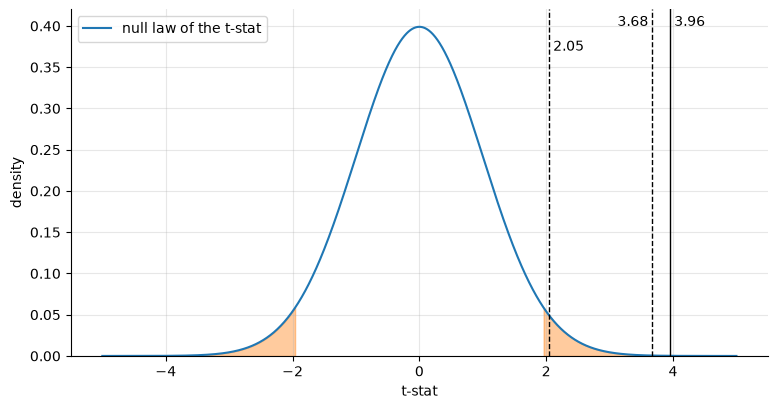

In [5]:
x = np.linspace(-5, 5, 2001)
gap = np.abs(stats.t.pdf(x, T - 1) - stats.norm.pdf(x)).max()
show("largest density gap", gap, ".1e", "2.3e-05")
show("t_5848 97.5% point", float(stats.t.isf(0.025, T - 1)), ".4f", "1.9604")
c = stats.norm.isf(0.025)
fig, ax = plt.subplots()
ax.plot(x, stats.norm.pdf(x), label="null law of the t-stat")
for side in (x <= -c, x >= c):
    ax.fill_between(x[side], 0, stats.norm.pdf(x[side]), color="C1", alpha=0.4)
for t, style, ha, y_ in ((t_all, "-", "left", 0.40), (tstat(R[pre]), "--", "left", 0.37),
                         (tstat(R[~pre]), "--", "right", 0.40)):
    ax.axvline(t, color="k", ls=style, lw=1)
    ax.text(t, y_, f" {t:.2f} ", ha=ha)
ax.set(xlabel="t-stat", ylabel="density", ylim=(0, 0.42))
ax.legend();

## Part 3 — Two groups and power

Example 4: the two-sample statistic (21.3) of the 10% regime against the 7% regime, by hand and with SciPy's `ttest_ind(..., equal_var=False)` (whose default, `equal_var=True`, pools the variances).

In [6]:
z_reg, se_reg = two_sample(R[~pre], R[pre])
show("SE of the difference (% a day)", 100 * se_reg, ".4f", "0.0315")
show("statistic (21.3)", z_reg, ".2f", "1.08")
show("p, normal", p2(z_reg), ".2f", "0.28")
show("p, SciPy (t reference)", float(stats.ttest_ind(R[~pre], R[pre], equal_var=False).pvalue), ".3f", "0.280")
show("from the printed inputs", (0.0804 - 0.0464) / sqrt(0.0227**2 + 0.0219**2), ".2f", "1.08")

SE of the difference (% a day): 0.0315   [book: 0.0315]
statistic (21.3): 1.08   [book: 1.08]
p, normal: 0.28   [book: 0.28]
p, SciPy (t reference): 0.280   [book: 0.280]
from the printed inputs: 1.08   [book: 1.08]


Exhibit 3 and Example 5: (21.4) for four annual Sharpe ratios, and the years for 80% power. TR23's annual ratio is $\sqrt A\,\bar R/s$ with $r_f=0$, LM19's statistic; on simple returns the factor $\sqrt A$ is a convention.

TR23's annual Sharpe ratio: 0.8115   [book: 0.8115]
the identity SR sqrt(years): 3.956   [book: 3.956]
years for 80% power at SR 1: 7.85   [book: 7.85]
years for 80% power at SR 0.8115: 11.9   [book: 11.9]
years for 80% power at SR 0.5: 31.4   [book: 31.4]
years for 80% power at SR 0.25: 125.6   [book: 125.6]
power over 23.76 years at SR 1: 0.998   [book: 0.998]
power over 23.76 years at SR 0.8115: 0.977   [book: 0.977]
power over 23.76 years at SR 0.5: 0.68   [book: 0.68]
power over 23.76 years at SR 0.25: 0.23   [book: 0.23]


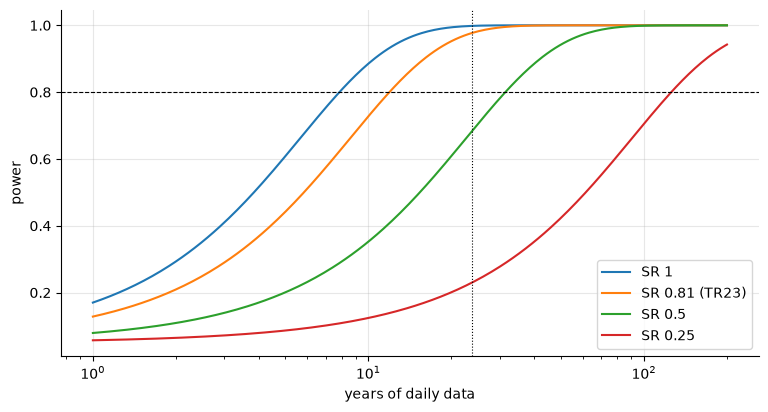

In [7]:
c975, c80 = stats.norm.isf(0.025), stats.norm.ppf(0.8)


def power(sr, yrs):
    d = sr * np.sqrt(yrs)
    return stats.norm.cdf(d - c975) + stats.norm.cdf(-d - c975)


sr_tr = sqrt(A) * Rbar / s
show("TR23's annual Sharpe ratio", sr_tr, ".4f", "0.8115")
show("the identity SR sqrt(years)", sr_tr * sqrt(years), ".3f", "3.956")
for sr, book in ((1, "7.85"), (sr_tr, "11.9"), (0.5, "31.4"), (0.25, "125.6")):
    show(f"years for 80% power at SR {sr:.4g}", ((c975 + c80) / sr) ** 2, f".{len(book.split('.')[1])}f", book)
for sr, book in ((1, "0.998"), (sr_tr, "0.977"), (0.5, "0.68"), (0.25, "0.23")):
    show(f"power over {years:.2f} years at SR {sr:.4g}", power(sr, years), f".{len(book.split('.')[1])}f", book)
yrs = np.logspace(0, np.log10(200), 300)
fig, ax = plt.subplots()
for sr, lab in ((1, "SR 1"), (sr_tr, "SR 0.81 (TR23)"), (0.5, "SR 0.5"), (0.25, "SR 0.25")):
    ax.plot(yrs, power(sr, yrs), label=lab)
ax.axhline(0.8, color="k", ls="--", lw=0.8)
ax.axvline(years, color="k", ls=":", lw=0.8)
ax.set(xscale="log", xlabel="years of daily data", ylabel="power")
ax.legend();

## Part 4 — Counts and independence

Example 1 (8 good months in 12, at 5%) and Problem 6 (9 in 12, at 10%) with `stats.binom`; then the months that give 80% power by the normal approximation, using $\hat\theta$'s standard deviation under each hypothesis, and an exact check.

In [8]:
# Example: 8 of 12 at 5%
show("Pr(X >= 8)", stats.binom.sf(7, 12, 0.5), ".3f", "0.194")
show("Pr(X >= 9)", stats.binom.sf(8, 12, 0.5), ".3f", "0.073")
show("size of X >= 10", stats.binom.sf(9, 12, 0.5), ".4f", "0.0193")
show("power at 0.55", stats.binom.sf(9, 12, 0.55), ".3f", "0.042")
# Problem 6 (a)-(c): 9 of 12 at 10%; the record lies on the region's edge, so its p-value is the size
assert Fraction(sum(comb(12, j) for j in range(9, 13)), 4096) == Fraction(299, 4096)
show("Problem 6 (a): Pr(X >= 9)", stats.binom.sf(8, 12, 0.5), ".4f", "0.0730")
assert stats.binom.sf(7, 12, 0.5) > 0.10 >= stats.binom.sf(8, 12, 0.5)     # the 10% region is X >= 9
show("Problem 6 (c): power of X >= 9 at 0.55", stats.binom.sf(8, 12, 0.55), ".3f", "0.134")

Pr(X >= 8): 0.194   [book: 0.194]
Pr(X >= 9): 0.073   [book: 0.073]
size of X >= 10: 0.0193   [book: 0.0193]
power at 0.55: 0.042   [book: 0.042]
Problem 6 (a): Pr(X >= 9): 0.0730   [book: 0.0730]
Problem 6 (c): power of X >= 9 at 0.55: 0.134   [book: 0.134]


months, normal approximation: 616.16   [book: 616.16]
n = 617 months (51.4 years): reject at X >= 330
exact size: 0.0454   [book: 0.0454]
exact power at 0.55: 0.7874   [book: 0.7874]
first n with exact power >= 80%: 620   [book: 620]
its cutoff: 331   [book: 331]
its size: 0.0498   [book: 0.0498]
its power: 0.8018   [book: 0.8018]


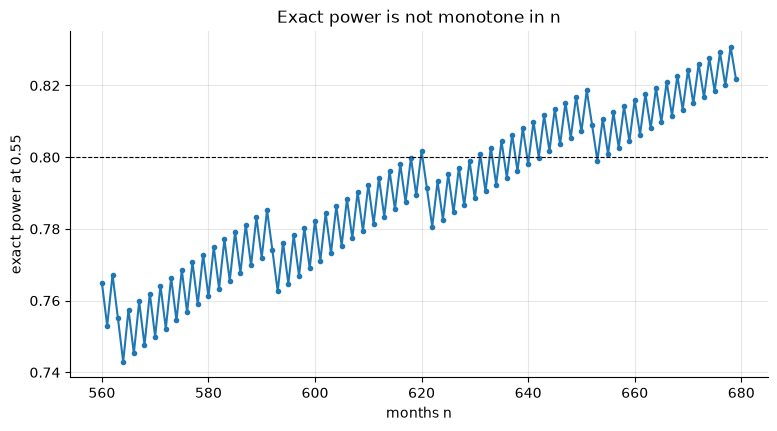

In [9]:
# Problem 6 (d): the one-sided 5% test of theta = 1/2 for n months, and its power at 0.55
def exact_test(n):
    cut = int(stats.binom.isf(0.05, n, 0.5)) + 1      # the smallest count whose upper tail is at most 5%
    while stats.binom.sf(cut - 1, n, 0.5) > 0.05:
        cut += 1
    return cut, stats.binom.sf(cut - 1, n, 0.5), stats.binom.sf(cut - 1, n, 0.55)


n_months = ((stats.norm.isf(0.05) * 0.5 + c80 * sqrt(0.55 * 0.45)) / 0.05) ** 2
show("months, normal approximation", n_months, ".2f", "616.16")
n = int(np.ceil(n_months))
cut, size_n, power_n = exact_test(n)
print(f"n = {n} months ({n / 12:.1f} years): reject at X >= {cut}")
show("exact size", size_n, ".4f", "0.0454")
show("exact power at 0.55", power_n, ".4f", "0.7874")
ns = np.arange(560, 680)
pw = np.array([exact_test(int(k))[2] for k in ns])
n80 = int(ns[np.argmax(pw >= 0.8)])
cut80, size80, power80 = exact_test(n80)
show("first n with exact power >= 80%", n80, "d", "620")
show("its cutoff", cut80, "d", "331")
show("its size", size80, ".4f", "0.0498")
show("its power", power80, ".4f", "0.8018")
fig, ax = plt.subplots()
ax.plot(ns, pw, ".-")
ax.axhline(0.8, color="k", ls="--", lw=0.8)
ax.set(xlabel="months n", ylabel="exact power at 0.55", title="Exact power is not monotone in n");

Example 6 and Exhibit 4: LM13's table of yesterday's and today's signs, counted exactly; the expected counts as fractions; (21.5) by hand, as $n\hat\rho^2$, and with SciPy, whose default applies Yates' correction.

In [10]:
down = [x < 0 for x in RF]
n11 = sum(a and b for a, b in zip(down[:-1], down[1:]))
n12 = sum(a and not b for a, b in zip(down[:-1], down[1:]))
n21 = sum(b and not a for a, b in zip(down[:-1], down[1:]))
n22 = sum(not a and not b for a, b in zip(down[:-1], down[1:]))
npair = n11 + n12 + n21 + n22
tab = np.array([[n11, n12], [n21, n22]])
rows_, cols_ = tab.sum(axis=1), tab.sum(axis=0)
expected = [[Fraction(int(r) * int(c_), npair) for c_ in cols_] for r in rows_]
print(tab, rows_, cols_)
print([[f"{float(e):,.2f}" for e in row] for row in expected])
chi2 = sum(float((tab[i, j] - expected[i][j]) ** 2 / expected[i][j]) for i in (0, 1) for j in (0, 1))
rho = (n11 * n22 - n12 * n21) / sqrt(rows_.prod() * cols_.prod())
show("chi2 by hand", chi2, ".2f", "2.69")
show("n rho^2", npair * rho**2, ".2f", "2.69")
show("rho", rho, ".4f", "0.0214")
show("p-value", float(stats.chi2.sf(chi2, 1)), ".2f", "0.10")
yates = stats.chi2_contingency(tab)                     # correction=True by default
show("SciPy default (Yates)", float(yates.statistic), ".2f", "2.60")
show("its p-value", float(yates.pvalue), ".3f", "0.107")
show("SciPy without the correction", float(stats.chi2_contingency(tab, correction=False).statistic), ".2f", "2.69")

[[1226 1417]
 [1418 1787]] [2643 3205] [2644 3204]
[['1,194.95', '1,448.05'], ['1,449.05', '1,755.95']]
chi2 by hand: 2.69   [book: 2.69]
n rho^2: 2.69   [book: 2.69]
rho: 0.0214   [book: 0.0214]
p-value: 0.10   [book: 0.10]
SciPy default (Yates): 2.60   [book: 2.60]
its p-value: 0.107   [book: 0.107]
SciPy without the correction: 2.69   [book: 2.69]


Example 7: falls of 3% or more after such a fall, counted exactly, against $\operatorname{Bin}(108,108/5{,}848)$. LM13's lab asked whether shares of falls after big moves exceed chance: this is one answer, and the clustering it reveals is why LM22 resamples blocks of days and LM26 models volatility.

In [11]:
fall = [x <= Fraction(-3, 100) for x in RF]
f1 = sum(fall[:-1])
f12 = sum(a and b for a, b in zip(fall[:-1], fall[1:]))
assert f12 == int(((R[:-1] <= -0.03 + EPS) & (R[1:] <= -0.03 + EPS)).sum())
print(f"{f1} days after a fall of 3% or more; {f12} of them fell 3% or more")
show("expected", Fraction(f1 * sum(fall[1:]), npair), ".1f", "2.0")
show("exact Pr(X >= 13)", float(stats.binom.sf(f12 - 1, f1, sum(fall[1:]) / npair)), ".1e", "1.2e-07")

108 days after a fall of 3% or more; 13 of them fell 3% or more
expected: 2.0   [book: 2.0]
exact Pr(X >= 13): 1.2e-07   [book: 1.2e-07]


## Part 5 — The calendar family

Exhibit 5: each month and weekday against all other returns with (21.3). Then experiment 8 (Example 8): the returns shuffled over TR23's fixed dates, `R[perm]` with `perm = rng.permutation(T)` drawn 10,000 times from one `rng = np.random.default_rng([8, 20261011])`, recomputing the 17 statistics each time. Model.

shape: (17, 5)
┌───────┬──────┬──────────┬───────────┬──────────┐
│ group ┆ days ┆ mean %   ┆ z         ┆ p        │
│ ---   ┆ ---  ┆ ---      ┆ ---       ┆ ---      │
│ str   ┆ i64  ┆ f64      ┆ f64       ┆ f64      │
╞═══════╪══════╪══════════╪═══════════╪══════════╡
│ Jan   ┆ 450  ┆ 0.045173 ┆ -0.321583 ┆ 0.747769 │
│ Feb   ┆ 369  ┆ 0.140535 ┆ 1.32621   ┆ 0.18477  │
│ Mar   ┆ 532  ┆ 0.005897 ┆ -1.042028 ┆ 0.297399 │
│ Apr   ┆ 477  ┆ 0.098152 ┆ 0.589449  ┆ 0.55556  │
│ May   ┆ 503  ┆ 0.089139 ┆ 0.513563  ┆ 0.607558 │
│ Jun   ┆ 498  ┆ 0.054655 ┆ -0.151566 ┆ 0.879529 │
│ Jul   ┆ 524  ┆ 0.113769 ┆ 1.004867  ┆ 0.314961 │
│ Aug   ┆ 522  ┆ 0.036127 ┆ -0.495321 ┆ 0.620374 │
│ Sep   ┆ 491  ┆ 0.005851 ┆ -1.126851 ┆ 0.259805 │
│ Oct   ┆ 482  ┆ 0.005482 ┆ -1.098033 ┆ 0.27219  │
│ Nov   ┆ 492  ┆ 0.046248 ┆ -0.336271 ┆ 0.736667 │
│ Dec   ┆ 509  ┆ 0.127021 ┆ 1.52545   ┆ 0.127147 │
│ Mon   ┆ 1151 ┆ 0.025421 ┆ -1.051252 ┆ 0.293143 │
│ Tue   ┆ 1181 ┆ 0.05954  ┆ -0.098475 ┆ 0.921555 │
│ Wed   ┆ 1183 ┆

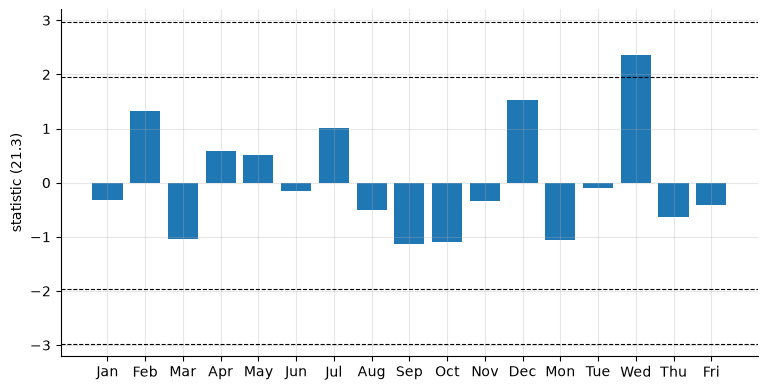

In [12]:
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
DAYS = ["Mon", "Tue", "Wed", "Thu", "Fri"]
groups = [(MONTHS[k - 1], mo == k) for k in range(1, 13)] + [(DAYS[k], wd == k) for k in range(5)]
fam = pl.DataFrame([{"group": g, "days": int(sel.sum()), "mean %": 100 * R[sel].mean(),
                     "z": two_sample(R[sel], R[~sel])[0]} for g, sel in groups])
pv = 2 * stats.norm.sf(np.abs(fam["z"].to_numpy()))           # two-sided normal p-values, (21.2)
fam = fam.with_columns(pl.Series("p", pv))
print(fam)
m = len(pv)
show("rejections at 5%", int((pv <= 0.05).sum()), "d", "1")
show("Wednesday's p", float(pv[14]), ".3f", "0.018")
show("expected false rejections", m * 0.05, ".2f", "0.85")
show("FWER if independent", 1 - 0.95**m, ".3f", "0.582")
show("Bonferroni-adjusted", m * pv.min(), ".2f", "0.31")
show("Sidak for independent tests", 1 - (1 - pv.min()) ** m, ".3f", "0.267")
fig, ax = plt.subplots()
ax.bar(fam["group"], fam["z"])
for y_ in (1.96, -1.96, stats.norm.isf(0.025 / m), -stats.norm.isf(0.025 / m)):
    ax.axhline(y_, color="k", ls="--", lw=0.8)
ax.set(ylabel="statistic (21.3)", ylim=(-3.2, 3.2));

In [13]:
g8 = np.random.default_rng([8, SEED])
grp_m, grp_w = mo - 1, wd
n_m = np.bincount(grp_m, minlength=12).astype(float)
n_w = np.bincount(grp_w, minlength=7)[:5].astype(float)
S_all, Q_all = R.sum(), (R * R).sum()
zmax = np.empty(10_000)
for b in range(10_000):
    x = R[g8.permutation(T)]
    zs = []
    for grp, cnt, K in ((grp_m, n_m, 12), (grp_w, n_w, 5)):   # (21.3) for every group at once, from sums
        s1 = np.bincount(grp, weights=x, minlength=12)[:K]
        q1 = np.bincount(grp, weights=x * x, minlength=12)[:K]
        c2 = T - cnt
        m1, m2 = s1 / cnt, (S_all - s1) / c2
        v1 = (q1 - cnt * m1**2) / (cnt - 1)
        v2 = (Q_all - q1 - c2 * m2**2) / (c2 - 1)
        zs.append((m1 - m2) / np.sqrt(v1 / cnt + v2 / c2))
    zmax[b] = np.abs(np.concatenate(zs)).max()
share_a = (zmax >= 1.959964 - EPS).mean()
share_b = (zmax >= abs(fam["z"][14]) - EPS).mean()
show("shuffles with a rejection", share_a, ".3f", "0.580")
show("its SE (18.2)", sqrt(share_a * (1 - share_a) / 10_000), ".3f", "0.005")
show("shuffles at least as extreme as Wednesday", share_b, ".3f", "0.266")
show("its SE (18.2)", sqrt(share_b * (1 - share_b) / 10_000), ".3f", "0.004")
for name, sel, book in (("before", pre, "2.06"), ("from", ~pre, "1.25")):
    x, w = R[sel], wd[sel]
    show(f"Wednesday {name} 1 June 2015", two_sample(x[w == 2], x[w != 2])[0], ".2f", book)

shuffles with a rejection: 0.580   [book: 0.580]
its SE (18.2): 0.005   [book: 0.005]
shuffles at least as extreme as Wednesday: 0.266   [book: 0.266]
its SE (18.2): 0.004   [book: 0.004]
Wednesday before 1 June 2015: 2.06   [book: 2.06]
Wednesday from 1 June 2015: 1.25   [book: 1.25]


## Part 6 — Holm and Benjamini–Hochberg

The three rules by hand on Example 9's constructed p-values, compared exactly as fractions; then the packages on the calendar family. `multipletests` defaults to Holm–Šidák (`method="hs"`), not Holm: always pass `method`.

On the calendar, Bonferroni and Holm stop at the first rank. Benjamini–Hochberg steps up, so every rank must be checked against its level $iq/m$. Its adjusted p-values are $\min_{j\ge i}mp_{(j)}/j$, capped at 1.

In [14]:
def bonferroni(p, a):
    return sum(pi <= a / len(p) for pi in p)


def holm(p, a):                       # (21.7): leading ranks with p_(i) <= a / (m - i + 1)
    k = 0
    for i, pi in enumerate(sorted(p)):
        if pi > a / (len(p) - i):
            break
        k += 1
    return k


def bh(p, q):                         # (21.8): the largest rank with p_(i) <= i q / m
    ok = [i + 1 for i, pi in enumerate(sorted(p)) if pi <= (i + 1) * q / len(p)]
    return max(ok, default=0)


e9 = [Fraction(v) for v in ("0.002", "0.0054", "0.0061", "0.011", "0.024", "0.031", "0.09", "0.22", "0.47", "0.86")]
a5 = Fraction(5, 100)
show("Bonferroni", bonferroni(e9, a5), "d", "1")
show("Holm", holm(e9, a5), "d", "3")
show("Benjamini-Hochberg", bh(e9, a5), "d", "5")
p10 = np.array([float(v) for v in e9])
for method, book in (("bonferroni", "1"), ("holm", "3"), ("fdr_bh", "5")):
    show(f"multipletests {method}", int(multipletests(p10, alpha=0.05, method=method)[0].sum()), "d", book)
print("calendar:", {meth: int(multipletests(pv, alpha=0.05, method=meth)[0].sum())
                    for meth in ("bonferroni", "holm", "fdr_bh", "hs")})
adj = np.sort(stats.false_discovery_control(pv, method="bh"))
show("smallest BH-adjusted p", adj[0], ".3f", "0.308")
ps = np.sort(pv)
ranks = np.arange(1, m + 1)
by_hand = np.minimum(1, np.minimum.accumulate((m * ps / ranks)[::-1])[::-1])   # min over j >= i of m p_(j) / j
assert np.allclose(by_hand, adj, rtol=0, atol=1e-15)
ratio10 = (ps / (ranks * 0.10 / m)).min()
print(f"smallest p_(i) / (i q / m) at q = 10%: {ratio10:.2f} (at least threefold)")
assert ratio10 >= 3

Bonferroni: 1   [book: 1]
Holm: 3   [book: 3]
Benjamini-Hochberg: 5   [book: 5]
multipletests bonferroni: 1   [book: 1]
multipletests holm: 3   [book: 3]
multipletests fdr_bh: 5   [book: 5]
calendar: {'bonferroni': 0, 'holm': 0, 'fdr_bh': 0, 'hs': 0}
smallest BH-adjusted p: 0.308   [book: 0.308]
smallest p_(i) / (i q / m) at q = 10%: 3.08 (at least threefold)


Exhibit 6: the calendar's sorted p-values against each rule's levels, on a log scale. No point lies on or below any line.

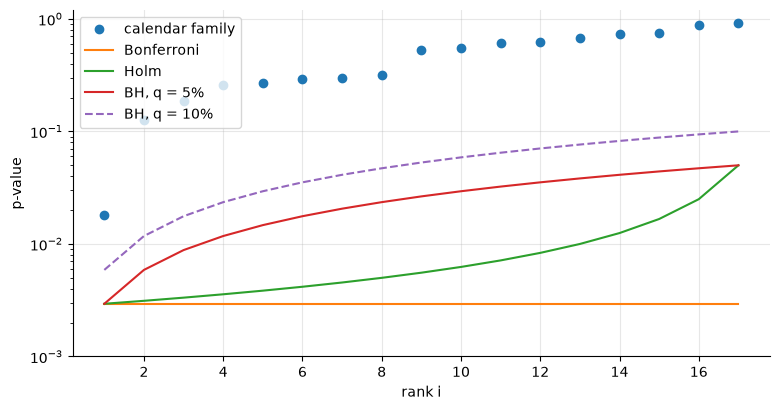

In [15]:
ps = np.sort(pv)
i = np.arange(1, m + 1)
fig, ax = plt.subplots()
ax.plot(i, ps, "o", label="calendar family")
ax.plot(i, np.full(m, 0.05 / m), label="Bonferroni")
ax.plot(i, 0.05 / (m - i + 1), label="Holm")
ax.plot(i, i * 0.05 / m, label="BH, q = 5%")
ax.plot(i, i * 0.10 / m, "--", label="BH, q = 10%")
ax.set(yscale="log", xlabel="rank i", ylabel="p-value", ylim=(1e-3, 1.2))
ax.legend();

## Part 7 — A search over random rules

Experiment 10 (Example 10): 10,000 rules, each long or short one unit by a fair coin each day, every position drawn in one call, `integers(0, 2, size=(10000, T), dtype=np.int8)`, with 1 for long and 0 for short; the t-stat (21.1) of each rule's daily returns, in 20 chunks of 500 rules. The standard deviation of the 10,000 t-stats gets LM18's batch standard error over the 20 chunks. Then (21.9) for the best of $m$ independent null statistics (Exhibit 7).

In [16]:
g10 = np.random.default_rng([10, SEED])
pos = g10.integers(0, 2, size=(10_000, T), dtype=np.int8)
tt = np.empty(10_000)
for c0 in range(0, 10_000, 500):
    xr = (2.0 * pos[c0:c0 + 500].astype(np.float64) - 1.0) * R
    tt[c0:c0 + 500] = xr.mean(axis=1) / (xr.std(axis=1, ddof=1) / np.sqrt(T))
sd = tt.std(ddof=0)
batch = np.array([tt[c0:c0 + 500].std(ddof=0) for c0 in range(0, 10_000, 500)])
show("mean t-stat", tt.mean(), ".2f", "-0.01")
show("its SE", sd / 100, ".2f", "0.01")
show("standard deviation", sd, ".3f", "0.995")
show("its batch SE", batch.std(ddof=0) / sqrt(20), ".3f", "0.007")
show("rules at t >= 3", int((tt >= 3 - EPS).sum()), "d", "13")
show("expected", 10_000 * stats.norm.sf(3), ".1f", "13.5")
best = np.maximum.accumulate(tt)
show("best of 100", best[99], ".2f", "2.95")
show("best of 1,000", best[999], ".2f", "2.95")
show("rule 1,022", tt[1021], ".2f", "3.28")
show("best of 10,000", best[-1], ".2f", "3.97")
records = [k for k in range(10_000) if k == 0 or tt[k] > best[k - 1]]
print("records (rule, t-stat):", [(k + 1, round(float(tt[k]), 2)) for k in records])

mean t-stat: -0.01   [book: -0.01]
its SE: 0.01   [book: 0.01]
standard deviation: 0.995   [book: 0.995]
its batch SE: 0.007   [book: 0.007]
rules at t >= 3: 13   [book: 13]
expected: 13.5   [book: 13.5]
best of 100: 2.95   [book: 2.95]
best of 1,000: 2.95   [book: 2.95]
rule 1,022: 3.28   [book: 3.28]
best of 10,000: 3.97   [book: 3.97]
records (rule, t-stat): [(1, -1.18), (3, -0.08), (4, 0.88), (8, 1.03), (12, 1.45), (14, 1.68), (45, 2.2), (90, 2.95), (1022, 3.28), (3846, 3.84), (7840, 3.97)]


median of the best of 17: 1.75   [book: 1.75]
median of the best of 100: 2.46   [book: 2.46]
median of the best of 1000: 3.20   [book: 3.20]
median of the best of 10000: 3.81   [book: 3.81]
Pr(best of 1,000 > 3): 0.74   [book: 0.74]
Bonferroni tests for t = 3: 18.5   [book: 18.5]
Bonferroni's level for the module's 29 tests: 3.134   [book: 3.134]


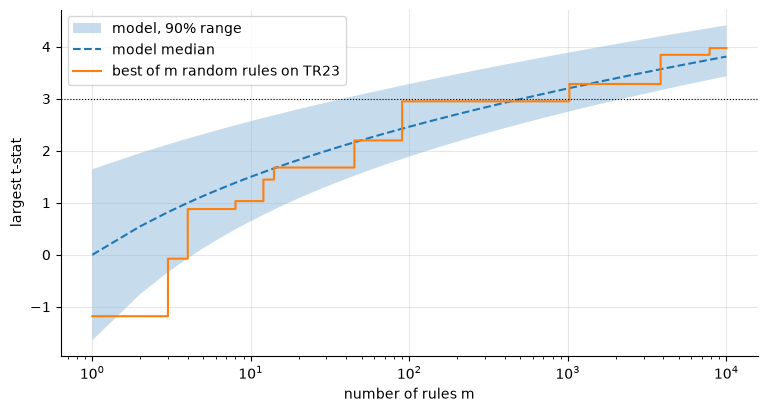

In [17]:
def max_quantile(u, m_):     # (21.9): Pr(max <= x) = Phi(x)^m, so the u quantile is Phi^-1(u^(1/m))
    return stats.norm.ppf(u ** (1 / m_))


for m_, book in ((17, "1.75"), (100, "2.46"), (1000, "3.20"), (10000, "3.81")):
    show(f"median of the best of {m_}", max_quantile(0.5, m_), ".2f", book)
show("Pr(best of 1,000 > 3)", 1 - stats.norm.cdf(3) ** 1000, ".2f", "0.74")
show("Bonferroni tests for t = 3", 0.05 / (2 * stats.norm.sf(3)), ".1f", "18.5")
show("Bonferroni's level for the module's 29 tests", stats.norm.isf(0.025 / 29), ".3f", "3.134")
assert t_all > stats.norm.isf(0.025 / 29) > 3      # TR23's mean clears both bars
mm = np.unique(np.round(np.logspace(0, 4, 200)).astype(int))
fig, ax = plt.subplots()
ax.fill_between(mm, max_quantile(0.05, mm), max_quantile(0.95, mm), alpha=0.25, label="model, 90% range")
ax.plot(mm, max_quantile(0.5, mm), "--", label="model median")
ax.step(np.arange(1, 10_001), best, where="post", label="best of m random rules on TR23")
ax.axhline(3, color="k", ls=":", lw=0.8)
ax.set(xscale="log", xlabel="number of rules m", ylabel="largest t-stat")
ax.legend();

## Part 8 — Practice problems

**Problem 7.** LM15's 292 blocks of 20 sessions: the variance of their up-day counts against the binomial and the dependence-adjusted model. Use the standard error of a variance of $n$ nearly normal draws, $\sigma_X^2\sqrt{2/n}$, with $\sigma_X^2$ the model's value. It is the square root of LM20's $\operatorname{Var}(s^2)\approx(\operatorname{Kurt}-1)\sigma^4/T$ at $\operatorname{Kurt}=3$, with $n$ draws in place of $T$. Then find the blocks needed to see the gap.

In [18]:
nb = T // 20
blk = (R[: nb * 20] > EPS).reshape(nb, 20).sum(axis=1)
v = blk.var(ddof=0)
p_hat = blk.sum() / (nb * 20)
show("blocks' variance", v, ".2f", "4.72")
show("binomial 20 p q", 20 * p_hat * (1 - p_hat), ".2f", "4.95")
show("z against 4.95 (printed inputs)", (4.72 - 4.95) / (4.95 * sqrt(2 / 292)), ".2f", "-0.56")
show("z against 5.16 (printed inputs)", (4.72 - 5.16) / (5.16 * sqrt(2 / 292)), ".2f", "-1.03")
n_blk = 2 * (c975 * 4.95 / 0.21) ** 2
show("blocks", n_blk, ",.1f", "4,268.7")
print(f"{int(np.ceil(n_blk)):,} blocks = {20 * int(np.ceil(n_blk)):,} sessions = {20 * int(np.ceil(n_blk)) / A:.0f} years")

blocks' variance: 4.72   [book: 4.72]
binomial 20 p q: 4.95   [book: 4.95]
z against 4.95 (printed inputs): -0.56   [book: -0.56]
z against 5.16 (printed inputs): -1.03   [book: -1.03]
blocks: 4,268.7   [book: 4,268.7]
4,269 blocks = 85,380 sessions = 347 years


**Problem 9.** Jarque–Bera as SciPy computes it (divisor-$T$ moments), from LM14's printed moments and from the data; the $\chi^2_2$ tail $e^{-\mathrm{JB}/2}$ underflows, so compare its base-10 logarithm.

In [19]:
jb_printed = T / 6 * (0.34**2 + 5.27**2 / 4)
jb = stats.jarque_bera(R)
show("JB from -0.34 and 5.27", jb_printed, ",.0f", "6,881")
show("JB from the data", float(jb.statistic), ",.0f", "6,875")
print("SciPy's p-value:", jb.pvalue, "(underflows to 0)")
show("log10 of the p-value, printed inputs", -jb_printed / (2 * log(10)), ".0f", "-1494")
show("log10 of the p-value, data", -float(jb.statistic) / (2 * log(10)), ".0f", "-1493")

JB from -0.34 and 5.27: 6,881   [book: 6,881]
JB from the data: 6,875   [book: 6,875]
SciPy's p-value: 0.0 (underflows to 0)
log10 of the p-value, printed inputs: -1494   [book: -1494]
log10 of the p-value, data: -1493   [book: -1493]


**Problem 10.** The calendar family through the packages: `multipletests` with `method="holm"`, `"fdr_bh"` and without a method (Holm–Šidák), and `stats.false_discovery_control`.

In [20]:
for method in ("holm", "fdr_bh"):
    rej, adj_p, _, _ = multipletests(pv, alpha=0.05, method=method)
    print(f"{method}: {int(rej.sum())} rejected; smallest adjusted p {adj_p.min():.3f}")
rej, adj_p, _, _ = multipletests(pv, alpha=0.05)
print(f"default (Holm-Sidak): {int(rej.sum())} rejected")
show("Holm's first level", 0.05 / m, ".5f", "0.00294")
show("Holm-Sidak's first level", 1 - 0.95 ** (1 / m), ".5f", "0.00301")
print("BH rejects:", int((stats.false_discovery_control(pv) <= 0.05).sum()))
adj = np.sort(stats.false_discovery_control(pv))
show("BH-adjusted, smallest", adj[0], ".3f", "0.308")
show("BH-adjusted, second", adj[1], ".3f", "0.669")

holm: 0 rejected; smallest adjusted p 0.308
fdr_bh: 0 rejected; smallest adjusted p 0.308
default (Holm-Sidak): 0 rejected
Holm's first level: 0.00294   [book: 0.00294]
Holm-Sidak's first level: 0.00301   [book: 0.00301]
BH rejects: 0
BH-adjusted, smallest: 0.308   [book: 0.308]
BH-adjusted, second: 0.669   [book: 0.669]


**Problem 11.** Ten thousand families of 17 independent standard normal statistics, from `default_rng([11, 20261011])`. Model.

In [21]:
Z = np.random.default_rng([11, SEED]).standard_normal((10_000, 17))
c_b = stats.norm.isf(0.025 / 17)
f_u = (np.abs(Z) >= c975 - EPS).any(axis=1).mean()
f_b = (np.abs(Z) >= c_b - EPS).any(axis=1).mean()
show("Bonferroni level", c_b, ".3f", "2.974")
show("share with a rejection, unadjusted", f_u, ".3f", "0.590")
show("its SE", sqrt(f_u * (1 - f_u) / 10_000), ".3f", "0.005")
show("exact", 1 - 0.95**17, ".3f", "0.582")
show("share with a rejection, Bonferroni", f_b, ".3f", "0.051")
show("its SE", sqrt(f_b * (1 - f_b) / 10_000), ".3f", "0.002")
show("exact", 1 - (1 - 0.05 / 17) ** 17, ".5f", "0.04884")

Bonferroni level: 2.974   [book: 2.974]
share with a rejection, unadjusted: 0.590   [book: 0.590]
its SE: 0.005   [book: 0.005]
exact: 0.582   [book: 0.582]
share with a rejection, Bonferroni: 0.051   [book: 0.051]
its SE: 0.002   [book: 0.002]
exact: 0.04884   [book: 0.04884]


### Extension: the calendar family in each limit regime

Split TR23 at 1 June 2015 and run the 17 calendar tests within each regime: 34 tests, each group against the other days of its own regime. Apply Holm and Benjamini–Hochberg at 5% to all 34 together. Does Wednesday survive in either regime? Does any month? 32 of these 34 tests are new, since Wednesday in each regime is among the module's 29: the data now carry 61 tests. This is a stability check, not a new discovery.

In [22]:
regime_p = []
for name, sel in (("to 29 May 2015", pre), ("from 1 June 2015", ~pre)):
    x, w, mth = R[sel], wd[sel], mo[sel]
    for g, gsel in [(MONTHS[k - 1], mth == k) for k in range(1, 13)] + [(DAYS[k], w == k) for k in range(5)]:
        regime_p.append((name, g, p2(two_sample(x[gsel], x[~gsel])[0])))
print(f"{len(regime_p)} tests; smallest p-values:", sorted(regime_p, key=lambda r: r[2])[:3])
# your code: apply holm() and bh() (or multipletests) to the 34 p-values

34 tests; smallest p-values: [('to 29 May 2015', 'Wed', 0.03963362493871675), ('to 29 May 2015', 'Dec', 0.09792982601401344), ('from 1 June 2015', 'Mar', 0.110950589291593)]
